# InspectAI — PatchCore Hyperparameter Experiments

We compare **coreset sizes 400, 800, and 1600** while keeping the CNN, 256×256 preprocessing, split, and scoring fixed. Hyperparameters are compared using **synthetic defects created from the 44 held-out normal validation images**. The official MVTec test set is **not loaded or scored** here.

Synthetic validation is a *proxy*, not proof that a model will improve on real defects. The previous test-set results have already been seen; future real-test evaluation must be reported as exploratory.

## 1. Setup
Reuse the same split and feature architecture as `03_patchcore.ipynb`. No new dependencies beyond that notebook.

In [1]:
from pathlib import Path
import json, time
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageDraw
import torch
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.models import resnet18, ResNet18_Weights
from torchvision.models.feature_extraction import create_feature_extractor
from sklearn.metrics import roc_auc_score, average_precision_score

DATA_DIR = Path('../data/raw/metal_nut').resolve()
SPLIT_FILE = Path('../results/normal_split.json').resolve()
RESULTS_DIR = Path('../results').resolve()
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
DEVICE = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
SEED, IMAGE_SIZE, BATCH_SIZE = 42, 256, 8
NUM_CANDIDATES, PROJECTION_DIM, DISTANCE_CHUNK_SIZE = 4000, 64, 1024
CORESET_SIZES = (400, 800, 1600)
PIXEL_EVAL_SIZE = 128
np.random.seed(SEED)
torch.manual_seed(SEED)

assert DATA_DIR.is_dir() and SPLIT_FILE.is_file()
with SPLIT_FILE.open() as f:
    split = json.load(f)
normal_dir = DATA_DIR / 'train' / 'good'
train_paths = [normal_dir / p for p in split['train']]
val_paths = [normal_dir / p for p in split['validation']]
assert len(train_paths) == 176 and len(val_paths) == 44
assert set(train_paths).isdisjoint(val_paths)
print('Device:', DEVICE, '| Train:', len(train_paths), '| Validation:', len(val_paths))

Device: mps | Train: 176 | Validation: 44


## 2. Preprocessing and frozen spatial features
We match our existing PatchCore implementation: ImageNet-normalized 256×256 inputs, ResNet18 `layer2` and `layer3`, 3×3 local pooling, and bilinear feature alignment.

In [2]:
preprocess = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
])
class PathDataset(Dataset):
    def __init__(self, paths): self.paths = list(paths)
    def __len__(self): return len(self.paths)
    def __getitem__(self, i):
        with Image.open(self.paths[i]) as im:
            return preprocess(im.convert('RGB'))
train_loader = DataLoader(PathDataset(train_paths), batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

backbone = resnet18(weights=ResNet18_Weights.DEFAULT)
feature_extractor = create_feature_extractor(backbone, return_nodes={'layer2': 'layer2', 'layer3': 'layer3'}).to(DEVICE).eval()
for p in feature_extractor.parameters(): p.requires_grad_(False)

@torch.inference_mode()
def extract_patch_embeddings(images):
    features = feature_extractor(images.to(DEVICE))
    l2 = F.avg_pool2d(features['layer2'], 3, stride=1, padding=1)
    l3 = F.avg_pool2d(features['layer3'], 3, stride=1, padding=1)
    l3 = F.interpolate(l3, size=l2.shape[-2:], mode='bilinear', align_corners=False)
    return torch.cat([l2, l3], dim=1)

@torch.inference_mode()
def embeddings_as_patches(images):
    e = extract_patch_embeddings(images)
    return e.permute(0, 2, 3, 1).reshape(-1, e.shape[1]).cpu()

train_bank = torch.cat([embeddings_as_patches(x) for x in train_loader], dim=0)
print('Training patch bank:', tuple(train_bank.shape))

Training patch bank: (180224, 384)


## 3. Approximate coreset selection
Run the same fixed-seed candidate projection/greedy selection as the initial model. We select a **nested ordering** once: the first 400/800/1600 points produce comparable banks.

In [3]:
def select_nested_coresets(bank, sizes=CORESET_SIZES):
    generator = torch.Generator().manual_seed(SEED)
    candidate_idx = torch.randperm(len(bank), generator=generator)[:NUM_CANDIDATES]
    candidates = bank[candidate_idx]
    projection = torch.randn(candidates.shape[1], PROJECTION_DIM, generator=generator) / np.sqrt(PROJECTION_DIM)
    projected = candidates @ projection
    nearest_sq = torch.full((len(candidates),), float('inf'))
    selected = []
    current = 0
    for _ in range(max(sizes)):
        selected.append(current)
        d_sq = (projected - projected[current]).square().sum(dim=1)
        nearest_sq = torch.minimum(nearest_sq, d_sq)
        nearest_sq[selected] = -1
        current = int(torch.argmax(nearest_sq))
    return {k: candidates[selected[:k]].contiguous() for k in sizes}

start = time.perf_counter()
banks = select_nested_coresets(train_bank)
print('Coresets:', {k: tuple(v.shape) for k, v in banks.items()})
print('Selection seconds:', round(time.perf_counter() - start, 2))

Coresets: {400: (400, 384), 800: (800, 384), 1600: (1600, 384)}
Selection seconds: 0.19


## 4. Synthetic anomaly validation
For each of the 44 held-out normal images, create **one synthetic scratch** and **one color irregularity**; keep the original normal image as well. Masks are generated with the modifications. These are not real MVTec test defects and are used **only for development**.

Synthetic validation images: 132 | positives: 88


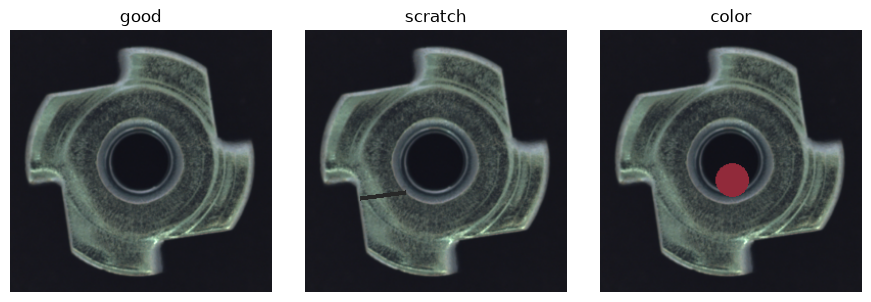

In [4]:
def make_synthetic(im, kind, seed):
    rng = np.random.default_rng(seed)
    image = im.convert('RGB').resize((IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.BILINEAR)
    modified = image.copy()
    mask = Image.new('L', image.size, 0)
    draw = ImageDraw.Draw(modified)
    mask_draw = ImageDraw.Draw(mask)
    if kind == 'scratch':
        cx, cy = int(rng.integers(65, 190)), int(rng.integers(65, 190))
        dx, dy = int(rng.integers(22, 57)), int(rng.integers(-48, 49))
        width = int(rng.integers(3, 8))
        line = [(cx-dx//2, cy-dy//2), (cx+dx//2, cy+dy//2)]
        color = (int(rng.integers(12, 45)),)*3
        draw.line(line, fill=color, width=width)
        mask_draw.line(line, fill=255, width=width)
    elif kind == 'color':
        cx, cy = int(rng.integers(70, 187)), int(rng.integers(70, 187))
        radius = int(rng.integers(11, 25))
        box = (cx-radius, cy-radius, cx+radius, cy+radius)
        draw.ellipse(box, fill=(145, 42, 58))
        mask_draw.ellipse(box, fill=255)
    else:
        raise ValueError(kind)
    return modified, np.asarray(mask, dtype=np.uint8)

val_images, val_masks, val_labels, val_kinds = [], [], [], []
for i, path in enumerate(val_paths):
    with Image.open(path) as raw:
        original = raw.convert('RGB').resize((IMAGE_SIZE, IMAGE_SIZE), Image.Resampling.BILINEAR)
        val_images.append(original)
        val_masks.append(np.zeros((IMAGE_SIZE, IMAGE_SIZE), dtype=np.uint8))
        val_labels.append(0)
        val_kinds.append('good')
        for j, kind in enumerate(['scratch', 'color']):
            changed, mask = make_synthetic(original, kind, SEED + 100*i + j)
            val_images.append(changed)
            val_masks.append(mask)
            val_labels.append(1)
            val_kinds.append(kind)
val_labels = np.array(val_labels)
val_kinds = np.array(val_kinds)
val_masks = np.stack(val_masks)
assert len(val_images) == 132
print('Synthetic validation images:', len(val_images), '| positives:', sum(val_labels))

fig, axes = plt.subplots(1, 3, figsize=(9, 3))
for ax, index in zip(axes, [0, 1, 2]):
    ax.imshow(val_images[index]); ax.set_title(val_kinds[index]); ax.axis('off')
plt.tight_layout(); plt.show()

## 5. Cache validation features once
All configurations use the exact same CNN embeddings. Only the memory-bank size changes. This makes the comparison more efficient and controlled.

In [5]:
class PILDataset(Dataset):
    def __init__(self, imgs): self.imgs = imgs
    def __len__(self): return len(self.imgs)
    def __getitem__(self, i): return preprocess(self.imgs[i])
val_loader = DataLoader(PILDataset(val_images), batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
with torch.inference_mode():
    all_embeddings = []
    for batch in val_loader:
        e = extract_patch_embeddings(batch)
        all_embeddings.append(e.cpu())
val_embeddings = torch.cat(all_embeddings)
print('Validation spatial embeddings:', tuple(val_embeddings.shape))

Validation spatial embeddings: (132, 384, 32, 32)


## 6. Compare the coreset sizes
We compute **synthetic-validation** image AUROC, pixel AUROC/AP, and inference time. We do not access official test data. The image score is maximum patch distance, just like our first PatchCore model.

In [6]:
@torch.inference_mode()
def evaluate_bank(bank):
    on_device = bank.to(DEVICE).float()
    all_scores, all_maps = [], []
    start = time.perf_counter()
    for e in val_embeddings.split(BATCH_SIZE):
        e = e.to(DEVICE)
        b, c, h, w = e.shape
        patches = e.permute(0, 2, 3, 1).reshape(-1, c)
        minimums = []
        for piece in patches.split(DISTANCE_CHUNK_SIZE):
            minimums.append(torch.cdist(piece.float(), on_device).min(1).values)
        maps = torch.cat(minimums).reshape(b, h, w)
        all_scores.append(maps.flatten(1).max(1).values.cpu().numpy())
        all_maps.append(maps.cpu())
    elapsed = time.perf_counter() - start
    scores = np.concatenate(all_scores)
    maps = torch.cat(all_maps)
    resized = F.interpolate(maps.unsqueeze(1), size=(PIXEL_EVAL_SIZE, PIXEL_EVAL_SIZE), mode='bilinear', align_corners=False).squeeze(1).numpy()
    masks = np.stack([np.asarray(Image.fromarray(m).resize((PIXEL_EVAL_SIZE, PIXEL_EVAL_SIZE), Image.Resampling.NEAREST)) > 0 for m in val_masks])
    normal = scores[val_labels == 0]
    return {
        'synthetic_image_auroc': float(roc_auc_score(val_labels, scores)),
        'synthetic_image_ap': float(average_precision_score(val_labels, scores)),
        'synthetic_pixel_auroc': float(roc_auc_score(masks.ravel(), resized.ravel())),
        'synthetic_pixel_ap': float(average_precision_score(masks.ravel(), resized.ravel())),
        'normal_p95_score': float(np.percentile(normal, 95)),
        'scoring_seconds_per_image': float(elapsed/len(scores)),
    }

results = {}
for size, bank in banks.items():
    metrics = evaluate_bank(bank)
    results[size] = metrics
    print(f'\nCoreset size: {size}')
    for k, v in metrics.items(): print(f'  {k}: {v:.4f}')

out = RESULTS_DIR / 'patchcore_coreset_sweep.json'
with out.open('w') as f: json.dump({'protocol': 'synthetic-validation-only', 'results': results}, f, indent=2)
print('\nSaved:', out)


Coreset size: 400
  synthetic_image_auroc: 0.9868
  synthetic_image_ap: 0.9945
  synthetic_pixel_auroc: 0.9969
  synthetic_pixel_ap: 0.8348
  normal_p95_score: 2.5466
  scoring_seconds_per_image: 0.0010

Coreset size: 800
  synthetic_image_auroc: 0.9951
  synthetic_image_ap: 0.9977
  synthetic_pixel_auroc: 0.9976
  synthetic_pixel_ap: 0.8382
  normal_p95_score: 2.3870
  scoring_seconds_per_image: 0.0008

Coreset size: 1600
  synthetic_image_auroc: 0.9954
  synthetic_image_ap: 0.9978
  synthetic_pixel_auroc: 0.9977
  synthetic_pixel_ap: 0.8403
  normal_p95_score: 2.3454
  scoring_seconds_per_image: 0.0014

Saved: /Users/chkhai/Documents/projects/inspectAI/results/patchcore_coreset_sweep.json


## 7. Visualize comparisons and select a candidate
Choose primarily using synthetic image AUROC, with synthetic pixel AP as the tie-breaker. **Do not claim the selected configuration has improved official-test AUROC.**

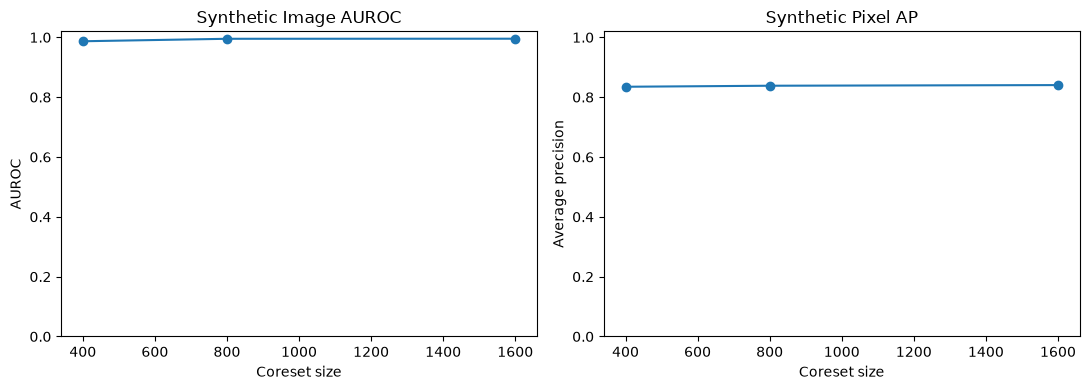

Selected for further development (synthetic validation only): 1600
Existing production/demo bank remains unchanged: models/patchcore_final_bank.pt


In [7]:
sizes = list(results)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(sizes, [results[s]['synthetic_image_auroc'] for s in sizes], marker='o')
axes[0].set_title('Synthetic Image AUROC'); axes[0].set_xlabel('Coreset size'); axes[0].set_ylabel('AUROC'); axes[0].set_ylim(0, 1.02)
axes[1].plot(sizes, [results[s]['synthetic_pixel_ap'] for s in sizes], marker='o')
axes[1].set_title('Synthetic Pixel AP'); axes[1].set_xlabel('Coreset size'); axes[1].set_ylabel('Average precision'); axes[1].set_ylim(0, 1.02)
plt.tight_layout()
plot_path = RESULTS_DIR / 'figures' / 'patchcore_coreset_sweep.png'
plot_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(plot_path, dpi=130, bbox_inches='tight')
plt.show()
selected_size = max(sizes, key=lambda s: (results[s]['synthetic_image_auroc'], results[s]['synthetic_pixel_ap']))
print('Selected for further development (synthetic validation only):', selected_size)
print('Existing production/demo bank remains unchanged: models/patchcore_final_bank.pt')

## 8. Log finished runs to DagsHub (optional)
All computation and results are saved locally before network logging. Each coreset size becomes its own MLflow run. A timeout won't invalidate or erase the results.

In [8]:
LOG_TO_DAGSHUB = True
if LOG_TO_DAGSHUB:
    try:
        import dagshub, mlflow
        dagshub.init(repo_owner='lchkh23', repo_name='inspectAI', mlflow=True)
        mlflow.set_experiment('metal-nut-anomaly-detection')
        for size in sizes:
            with mlflow.start_run(run_name=f'patchcore-synthetic-coreset-{size}'):
                mlflow.log_params({
                    'model': 'simplified_patchcore', 'backbone': 'resnet18',
                    'input_size': IMAGE_SIZE, 'feature_layers': 'layer2+layer3',
                    'coreset_size': size, 'candidate_count': NUM_CANDIDATES,
                    'projection_dim': PROJECTION_DIM, 'seed': SEED,
                    'selection_dataset': 'synthetic_validation', 'official_test_used': False,
                    'train_images': len(train_paths), 'validation_normal_images': len(val_paths),
                    'synthetic_anomalies_per_normal': 2,
                })
                mlflow.log_metrics(results[size])
                mlflow.log_artifact(str(out), artifact_path='results')
                mlflow.log_artifact(str(plot_path), artifact_path='figures')
        print('Logged all coreset experiments to DagsHub.')
    except Exception as e:
        print('Remote logging failed; local JSON and figure are intact:', type(e).__name__, str(e)[:300])
        try:
            if mlflow.active_run() is not None: mlflow.end_run(status='FAILED')
        except Exception: pass

Accessing as lchkh23

Initialized MLflow to track repo "lchkh23/inspectAI"

Repository lchkh23/inspectAI initialized!

🏃 View run patchcore-synthetic-coreset-400 at: https://dagshub.com/lchkh23/inspectAI.mlflow/#/experiments/1/runs/9556a6b9b1084303b1f5d76f8ad29522
🧪 View experiment at: https://dagshub.com/lchkh23/inspectAI.mlflow/#/experiments/1
🏃 View run patchcore-synthetic-coreset-800 at: https://dagshub.com/lchkh23/inspectAI.mlflow/#/experiments/1/runs/02c31d3b86d94618a8f3db07f2d16188
🧪 View experiment at: https://dagshub.com/lchkh23/inspectAI.mlflow/#/experiments/1
🏃 View run patchcore-synthetic-coreset-1600 at: https://dagshub.com/lchkh23/inspectAI.mlflow/#/experiments/1/runs/f9ce7340695347389912459271d6fc77
🧪 View experiment at: https://dagshub.com/lchkh23/inspectAI.mlflow/#/experiments/1
Logged all coreset experiments to DagsHub.


## Interpretation and limitations
- We changed only coreset size, not the backbone, resolution, or scoring rule.
- The 44 validation images were kept out of training memory banks.
- Scratch and color anomalies here were **synthetically drawn**, not real defects; reported metrics **cannot be compared directly** with official MVTec test metrics.
- Choosing a new best model on the already-reviewed official test set would bias evaluation. Keep the original demo model unchanged until a well-documented model-update decision.
- The nested coreset ordering is consistent across sizes; it can differ from fully independent coreset selections.
- The current comparison is exploratory and uses a single seed. Repeated seeds or independent new data would strengthen confidence.

In [9]:
experiment = mlflow.get_experiment_by_name(
    "metal-nut-anomaly-detection"
)

runs = mlflow.search_runs(
    experiment_ids=[experiment.experiment_id],
    output_format="list"
)

for run in runs:
    if run.data.tags.get("mlflow.runName", "").startswith(
        "patchcore-synthetic-coreset-"
    ):
        print("\nRun:", run.data.tags["mlflow.runName"])
        print("Metrics:", run.data.metrics)


Run: patchcore-synthetic-coreset-1600
Metrics: {'synthetic_image_auroc': 0.9953512396694215, 'synthetic_image_ap': 0.9978257655405925, 'synthetic_pixel_auroc': 0.9977399380818518, 'synthetic_pixel_ap': 0.8403169760835565, 'normal_p95_score': 2.345418930053711, 'scoring_seconds_per_image': 0.0013602541060649717}

Run: patchcore-synthetic-coreset-800
Metrics: {'synthetic_image_auroc': 0.9950929752066116, 'synthetic_image_ap': 0.9976916228342614, 'synthetic_pixel_auroc': 0.9975689962894031, 'synthetic_pixel_ap': 0.8381781484130605, 'normal_p95_score': 2.3869845867156982, 'scoring_seconds_per_image': 0.0007790041060588644}

Run: patchcore-synthetic-coreset-400
Metrics: {'synthetic_image_auroc': 0.9868285123966942, 'synthetic_image_ap': 0.9944575708991084, 'synthetic_pixel_auroc': 0.9969315364183213, 'synthetic_pixel_ap': 0.8347623548502854, 'normal_p95_score': 2.5465753078460693, 'scoring_seconds_per_image': 0.0010492907196928145}


## Hyperparameter Tuning Conclusions

We evaluated PatchCore using three memory-bank sizes (400, 800, and 1600 patches) on synthetic anomalies generated from held-out normal images.

Increasing the memory bank from 400 to 800 improved synthetic-validation anomaly detection. Increasing it further to 1600 produced only marginal additional improvements.

The 1600-patch configuration achieved the highest synthetic-validation metrics, while the 800-patch configuration offered a favorable balance between performance and memory usage.

**Selected configuration:** 800 patches.

The official test set was not used during this hyperparameter sweep. Synthetic-validation performance does not guarantee equivalent performance on real industrial defects.